# O que o ECG diz sobre o paciente: avaliação honesta com 233 mil brasileiros

Projeto final da Trilha de Trainees Insper AI (Tom e Renata).

**Parte A:** uma CNN 1D detecta 6 alterações no ECG de 12 derivações. Avaliamos em pacientes que o modelo nunca viu, em outro país (PTB-XL, Alemanha) e contra um gabarito de especialistas (CODE-TEST).
**Parte B:** o ECG prevê morte em até X anos **além** do que a idade e o sexo já dizem?

**Por que esta base:** na fase 1 (MIT-BIH, `projeto_arritmia.ipynb`), mostramos que, com só 44 pacientes, o modelo decora as pessoas: o F1 macro cai de 0,89 (split aleatório) para 0,39 (pacientes novos). Aqui usamos a CODE-15%, com 233.770 pacientes.

**Como ler:** os títulos de seção ficam em células separadas, para recolher no VS Code. O plano e o log de decisões estão no `CLAUDE.md`.

**Como rodar:** no computador, com o kernel `.venv` (`requirements.txt`). No Colab, rodar direto (a célula de instalação cuida do resto). Os dados são baixados para a pasta `code15/` (fora do git).

## Glossário

**As 6 alterações** (rótulos da CODE-15%). Um mesmo ECG pode ter mais de uma (**multi-rótulo**).

| Rótulo | Nome | Em termos simples |
|---|---|---|
| **1dAVb** | Bloqueio atrioventricular de 1º grau | O sinal elétrico demora mais que o normal para passar dos átrios para os ventrículos |
| **RBBB** | Bloqueio de ramo direito | O sinal chega atrasado ao ventrículo direito; o QRS fica largo |
| **LBBB** | Bloqueio de ramo esquerdo | O mesmo, no ventrículo esquerdo |
| **SB** | Bradicardia sinusal | Ritmo de origem normal, mas lento |
| **ST** | Taquicardia sinusal | Ritmo de origem normal, mas rápido |
| **AF** | Fibrilação atrial | Os átrios "tremem" de forma desorganizada e os batimentos ficam irregulares |

**Termos**

| Termo | Significado |
|---|---|
| **ECG de 12 derivações** | O exame comum de consultório: o mesmo coração visto de 12 "ângulos" ao mesmo tempo. Aqui, cada exame é uma matriz de 4.096 instantes × 12 derivações. |
| **Multi-rótulo** | Em vez de escolher uma classe, o modelo responde 6 perguntas de sim/não, uma por alteração (saída *sigmoid*). |
| **Split por paciente** | Todos os exames de uma pessoa ficam no mesmo grupo (treino, validação ou teste). Sem isso, o modelo pode "reconhecer" a pessoa em vez da doença (foi o que vimos na fase 1). |
| **AUROC** | Chance de o modelo dar uma nota maior a um exame positivo sorteado do que a um negativo sorteado. 0,5 = chute; 1 = perfeito. Não depende de limiar. |
| **AUPRC** | Parecida, mas focada nos positivos. Mais exigente quando a alteração é rara. |
| **Horizonte (Parte B)** | "Morreu em até X anos depois do exame?". Só entra quem morreu dentro do prazo ou foi acompanhado pelo prazo inteiro. |
| **Idade do ECG** | Idade estimada só pelo ECG por um modelo de Lima et al. (2021). Se ela passa muito da idade real, o risco de morte é maior. |
| **PTB-XL / CODE-TEST** | Bases de teste: PTB-XL é alemã (outro país e outro aparelho); CODE-TEST tem 827 ECGs rotulados por vários médicos (gabarito). |

## 0. Status do projeto

Atualizar sempre que uma etapa mudar.

| Seção | Status |
|---|---|
| 1. Configuração | Pronto, rodado |
| 2. Dados | Pronto, rodado (parte 0) |
| 3. Exploração da tabela | Pronto, rodado |
| 4. Sinais: leitura e limpeza | Pronto, rodado (parte 0) |
| 5. Divisão por paciente | Pronto, rodado. Proporção 70/10/20 provisória |
| 6. Parte A: 6 alterações | A fazer |
| 7. Testes externos (PTB-XL, CODE-TEST) | A fazer |
| 8. Parte B: óbito | A fazer |
| 9. Conclusões | A fazer |

## 1. Configuração

Bibliotecas, seeds fixas (para os resultados se repetirem), nomes dos rótulos e cores fixas por rótulo, iguais em todos os gráficos.

In [1]:
# Instala o wfdb (leitura do PTB-XL) só se faltar, por exemplo no Colab.
# Instalar sem precisar pode atualizar numpy/pandas e quebrar outros pacotes.
try:
    import wfdb
except ImportError:
    %pip install -q wfdb

In [2]:
import random
import time
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DADOS = Path("code15")  # pasta dos dados (fora do git)
DADOS.mkdir(exist_ok=True)

ROTULOS = ["1dAVb", "RBBB", "LBBB", "SB", "ST", "AF"]
DERIVACOES = ["DI", "DII", "DIII", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]
CORES = dict(zip(ROTULOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
CINZA = "#555555"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})

## 2. Dados

Baixamos do Zenodo a tabela `exams.csv` (todos os 345.779 exames, sem os sinais) e as **partes** com os sinais que forem usadas (`PARTES`). Cada parte tem ~20 mil exames, ocupa 2,7 GB compactada e ~2 GB na memória depois de lida.

O Zenodo limita a velocidade de cada conexão (~0,3 MB/s), então o download é feito em 16 pedaços em paralelo. Só baixa o que ainda não está na pasta.

In [3]:
ZENODO = "https://zenodo.org/records/4916206/files"
PARTES = [0]  # quais partes dos sinais usar (de 0 a 17)


def baixar(url, destino, conexoes=16):
    """Baixa um arquivo grande em pedaços paralelos (HTTP Range), retomando conexões que caem."""
    with urllib.request.urlopen(urllib.request.Request(url, headers={"Range": "bytes=0-0"})) as r:
        total = int(r.headers["Content-Range"].split("/")[1])
    with open(destino, "wb") as f:
        f.truncate(total)
    passo = -(-total // conexoes)
    baixado = [0] * conexoes

    def pedaco(i):
        ini, fim = i * passo, min(total, (i + 1) * passo) - 1
        for _ in range(100):
            if baixado[i] >= fim - ini + 1:
                return
            try:
                pos = ini + baixado[i]
                req = urllib.request.Request(url, headers={"Range": f"bytes={pos}-{fim}"})
                with urllib.request.urlopen(req, timeout=60) as r, open(destino, "r+b") as f:
                    f.seek(pos)
                    while bloco := r.read(1 << 20):
                        f.write(bloco)
                        baixado[i] += len(bloco)
            except Exception as e:
                print(f"pedaço {i}: {e!r}, retomando")
                time.sleep(3)
        raise RuntimeError(f"pedaço {i} incompleto")

    with ThreadPoolExecutor(conexoes) as ex:
        list(ex.map(pedaco, range(conexoes)))
    assert sum(baixado) == total, "download incompleto"


if not (DADOS / "exams.csv").exists():
    urllib.request.urlretrieve(f"{ZENODO}/exams.csv?download=1", DADOS / "exams.csv")

for parte in PARTES:
    hdf5 = DADOS / f"exams_part{parte}.hdf5"
    if hdf5.exists():
        continue
    zip_ = DADOS / f"exams_part{parte}.zip"
    print(f"baixando parte {parte} (~2,7 GB)...")
    baixar(f"{ZENODO}/exams_part{parte}.zip?download=1", zip_)
    zipfile.ZipFile(zip_).extractall(DADOS)
    zip_.unlink()  # o zip não é mais necessário depois de extraído

tabela = pd.read_csv(DADOS / "exams.csv")
print(f"exames: {len(tabela):,} | pacientes: {tabela['patient_id'].nunique():,}")
tabela.head()

exames: 345,779 | pacientes: 233,770


,exam_id,age,is_male,nn_predicted_age,1dAVb,RBBB,LBBB,SB,ST,AF,patient_id,death,timey,normal_ecg,trace_file
0,1169160,38,True,40.160484,False,False,False,False,False,False,523632,False,2.098628,True,exams_part13.hdf5
1,2873686,73,True,67.059440,False,False,False,False,False,False,1724173,False,6.657529,False,exams_part13.hdf5
2,168405,67,True,79.621740,False,False,False,False,False,True,51421,False,4.282188,False,exams_part13.hdf5
3,271011,41,True,69.750260,False,False,False,False,False,False,1737282,False,4.038353,True,exams_part13.hdf5
4,384368,73,True,78.873460,False,False,False,False,False,False,331652,False,3.786298,False,exams_part13.hdf5


## 3. Exploração da tabela

Antes de olhar os sinais, entendemos a tabela inteira (os 345.779 exames): quão raras são as alterações, quantos exames cada pessoa tem, como a idade se relaciona com as alterações e com a morte, e como se comporta a "idade do ECG" do artigo de Lima et al.

### 3.1 Quão comuns são as alterações

**As 6 alterações são raras:** cada uma aparece em 1,6% a 2,8% dos exames. 89% dos exames não têm nenhuma das 6, e só 1% tem duas ou mais. Só 39% são marcados como "ECG normal": os outros têm alterações que não estão entre as 6.

Consequência: a acurácia não serve (chutar "não" sempre acerta ~98% em cada rótulo). Usamos AUROC e AUPRC por rótulo.

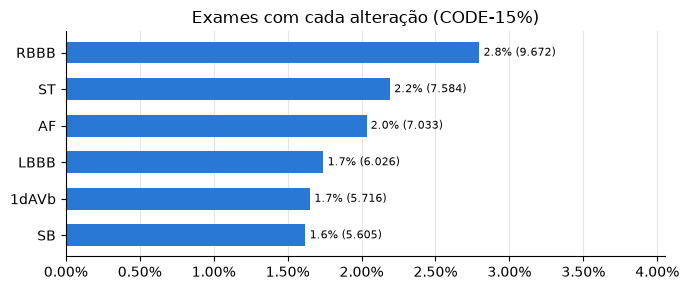

ECG normal (coluna normal_ecg): 38.9%
Número de alterações por exame: {0: 308004, 1: 34104, 2: 3486, 3: 180, 4: 5}


In [4]:
prevalencia = tabela[ROTULOS].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
barras = ax.barh(prevalencia.index, prevalencia.values, color=CORES["1dAVb"], height=0.6)
ax.bar_label(barras, labels=[f"{v:.1%} ({int(v * len(tabela)):,})".replace(",", ".") for v in prevalencia.values],
             padding=3, fontsize=8)
ax.set_xlim(0, prevalencia.max() * 1.45)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Exames com cada alteração (CODE-15%)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

n_alteracoes = tabela[ROTULOS].sum(axis=1)
print("ECG normal (coluna normal_ecg):", f"{tabela['normal_ecg'].mean():.1%}")
print("Número de alterações por exame:", n_alteracoes.value_counts().sort_index().to_dict())

### 3.2 Exames por paciente

29% dos pacientes têm mais de um exame, e eles somam **52% dos exames** (uma pessoa chega a ter 38). Se o split fosse por exame, metade dos dados poderia ter o mesmo paciente no treino e no teste. Por isso o split é por paciente (seção 5).

In [5]:
exames_por_paciente = tabela["patient_id"].value_counts()
resumo = exames_por_paciente.value_counts().sort_index()
print("pacientes com 1, 2, 3... exames:", resumo.head(6).to_dict(), "| máximo:", exames_por_paciente.max())
varios = exames_por_paciente[exames_por_paciente > 1]
print(f"{len(varios):,} pacientes ({len(varios) / len(exames_por_paciente):.0%}) têm mais de um exame; "
      f"eles somam {varios.sum():,} exames ({varios.sum() / len(tabela):.0%} do total).")

pacientes com 1, 2, 3... exames: {1: 166841, 2: 42222, 3: 14352, 4: 5664, 5: 2346, 6: 1156} | máximo: 38


66,929 pacientes (29%) têm mais de um exame; eles somam 178,938 exames (52% do total).


### 3.3 Idade, sexo e alterações

Idades de 17 a 100 anos (média 53), 40% homens. **Bloqueios de ramo, bloqueio AV e fibrilação atrial ficam muito mais comuns com a idade** (fibrilação atrial: ~0,1% antes dos 30 e ~7% aos 80+). Bradicardia e taquicardia quase não mudam.

Ou seja, a idade sozinha já "prevê" parte das alterações. Por isso o baseline A0 usa idade + sexo: a CNN precisa ganhar dele.

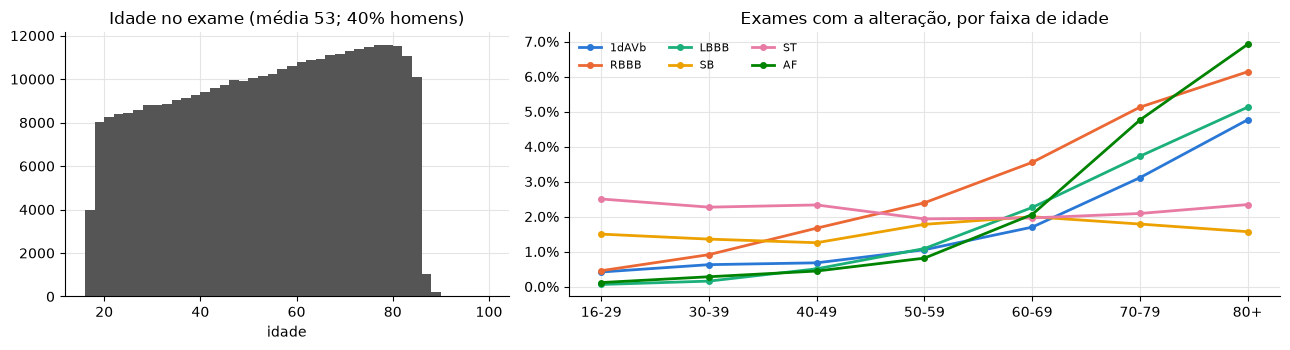

In [6]:
faixas = pd.cut(tabela["age"], bins=[16, 30, 40, 50, 60, 70, 80, 101], right=False,
                labels=["16-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"])
por_faixa = tabela.groupby(faixas, observed=True)[ROTULOS].mean()

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
eixos[0].hist(tabela["age"], bins=range(16, 102, 2), color=CINZA)
eixos[0].set_title(f"Idade no exame (média {tabela['age'].mean():.0f}; {tabela['is_male'].mean():.0%} homens)")
eixos[0].set_xlabel("idade")
for r in ROTULOS:
    eixos[1].plot(por_faixa.index.astype(str), por_faixa[r], marker="o", ms=4, lw=2, color=CORES[r], label=r)
eixos[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
eixos[1].set_title("Exames com a alteração, por faixa de idade")
eixos[1].legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

### 3.4 Óbito e horizontes

3,6% dos pacientes morreram no acompanhamento (mediana de 3,5 anos). A taxa sobe muito com a idade: **0,5% antes dos 40 e 13,9% aos 80+**.

Qualquer modelo de óbito precisa ser comparado com idade + sexo (B0); senão, ele pode só estar adivinhando a idade pelo ECG. A tabela mostra quantos pacientes e óbitos cada horizonte permite usar.

pacientes com acompanhamento: 233,647 | óbitos: 8,341 (3.6%)
anos de acompanhamento (p5, p25, mediana, p75, p95): [1.0, 2.1, 3.5, 5.2, 6.9]


,horizonte (anos),pacientes,óbitos,taxa
0,1,224869,2812,1.3%
1,2,185106,4716,2.5%
2,3,143779,6173,4.3%


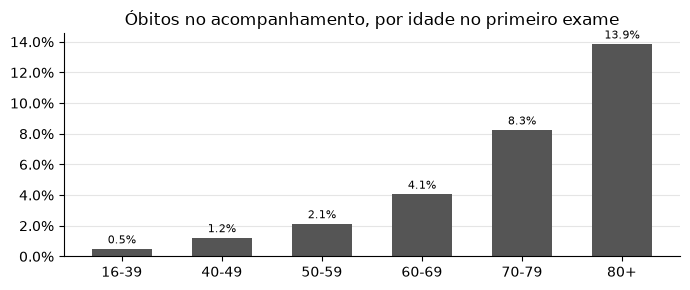

In [7]:
# death/timey só existem no primeiro exame de cada paciente
primeiro = tabela[tabela["death"].notna()].copy()
primeiro["death"] = primeiro["death"].astype(bool)
print(f"pacientes com acompanhamento: {len(primeiro):,} | óbitos: {primeiro['death'].sum():,} ({primeiro['death'].mean():.1%})")
print("anos de acompanhamento (p5, p25, mediana, p75, p95):", primeiro["timey"].quantile([.05, .25, .5, .75, .95]).round(1).tolist())

horizontes = []
for anos in (1, 2, 3):
    morreu_no_prazo = primeiro["death"] & (primeiro["timey"] <= anos)
    elegivel = morreu_no_prazo | (primeiro["timey"] >= anos)  # morreu no prazo ou foi acompanhado o prazo inteiro
    horizontes.append({"horizonte (anos)": anos, "pacientes": int(elegivel.sum()),
                       "óbitos": int(morreu_no_prazo[elegivel].sum()), "taxa": f"{morreu_no_prazo[elegivel].mean():.1%}"})
display(pd.DataFrame(horizontes))

faixa_primeiro = pd.cut(primeiro["age"], bins=[16, 40, 50, 60, 70, 80, 101], right=False,
                        labels=["16-39", "40-49", "50-59", "60-69", "70-79", "80+"])
taxa = primeiro.groupby(faixa_primeiro, observed=True)["death"].mean()
fig, ax = plt.subplots(figsize=(7, 3))
barras = ax.bar(taxa.index.astype(str), taxa.values, color=CINZA, width=0.6)
ax.bar_label(barras, labels=[f"{v:.1%}" for v in taxa.values], padding=2, fontsize=8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Óbitos no acompanhamento, por idade no primeiro exame")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 3.5 Idade do ECG (Lima et al., 2021)

A coluna `nn_predicted_age` erra em média 8,53 anos (correlação de 0,83), quase o mesmo do artigo (8,38; 0,84). Por isso tratamos essa coluna como a saída do modelo de Lima et al. (provável; não está documentado).

**Armadilha (paradoxo de Simpson):** comparando direto, quem tem o ECG "8+ anos mais velho" morre **menos** (3,0%) do que quem tem o ECG "8+ anos mais jovem" (4,6%), o contrário do artigo. Isso acontece porque os grupos têm idades reais diferentes: o grupo "ECG mais jovem" tem em média 63 anos, e o "ECG mais velho", 42. Provavelmente o modelo de idade "puxa para o meio": subestima os idosos e superestima os jovens. **Comparando dentro da mesma faixa de idade** (segunda tabela), o resultado do artigo aparece em todas as faixas. Por exemplo, aos 60-69 anos: 3,0%, 3,6% e 6,5%.

**Lição para a Parte B:** toda comparação de risco precisa levar a idade em conta.

erro médio absoluto: 8.53 anos | correlação: 0.83


,pacientes,taxa_de_obito,idade_media
ECG > 8 anos mais jovem,43121,4.6%,63
dentro de ±8 anos,134126,3.5%,50
ECG > 8 anos mais velho,56400,3.0%,42


,ECG > 8 anos mais jovem,dentro de ±8 anos,ECG > 8 anos mais velho
age,,,
16-39,0.3%,0.3%,0.8%
40-49,0.6%,0.8%,2.3%
50-59,1.1%,1.9%,3.4%
60-69,3.0%,3.6%,6.5%
70-79,6.5%,8.6%,11.0%
80+,12.4%,14.6%,21.4%


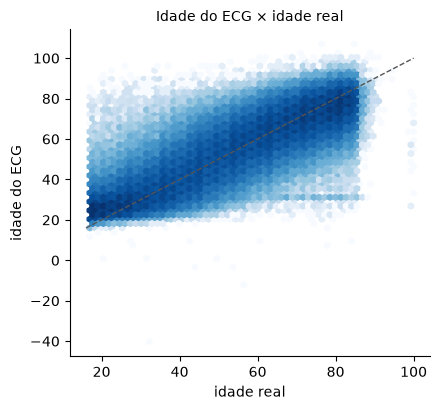

In [8]:
erro = tabela["nn_predicted_age"] - tabela["age"]
print(f"erro médio absoluto: {erro.abs().mean():.2f} anos | correlação: {tabela[['age', 'nn_predicted_age']].corr().iloc[0, 1]:.2f}")

diferenca = primeiro["nn_predicted_age"] - primeiro["age"]
grupo = pd.cut(diferenca, bins=[-np.inf, -8, 8, np.inf], labels=["ECG > 8 anos mais jovem", "dentro de ±8 anos", "ECG > 8 anos mais velho"])
# Comparação direta (mistura idades diferentes)
direto = primeiro.groupby(grupo, observed=True).agg(pacientes=("death", "size"), taxa_de_obito=("death", "mean"),
                                                    idade_media=("age", "mean"))
display(direto.style.format({"taxa_de_obito": "{:.1%}", "idade_media": "{:.0f}"}))

# Comparação dentro da mesma faixa de idade
faixa = pd.cut(primeiro["age"], bins=[16, 40, 50, 60, 70, 80, 101], right=False,
               labels=["16-39", "40-49", "50-59", "60-69", "70-79", "80+"])
display(primeiro.groupby([faixa, grupo], observed=True)["death"].mean().unstack().style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.hexbin(tabela["age"], tabela["nn_predicted_age"], gridsize=60, cmap="Blues", mincnt=1, bins="log")
ax.plot([16, 100], [16, 100], color=CINZA, lw=1, ls="--")
ax.set_xlabel("idade real")
ax.set_ylabel("idade do ECG")
ax.set_title("Idade do ECG × idade real", fontsize=10)
ax.grid(False)
plt.tight_layout()
plt.show()

## 4. Sinais: leitura e limpeza

Lemos os sinais das partes escolhidas e juntamos com a tabela pelo `exam_id`.

- Guardamos em **float16** (metade da memória do float32): ~2 GB por parte.
- Descartamos o `exam_id` 0 (linha de preenchimento que existe em cada parte) e os exames **todos zerados**.
- Exames de 7,3 s vêm completados com zeros até 4.096 amostras (10,24 s a 400 Hz). Isso fica como está; a decisão de como tratar vai para a Parte A.

In [9]:
def carregar_partes(partes):
    """Lê os sinais das partes, junta com a tabela e descarta exames vazios."""
    sinais, ids = [], []
    for parte in partes:
        with h5py.File(DADOS / f"exams_part{parte}.hdf5", "r") as f:
            sinais.append(f["tracings"][:].astype(np.float16))
            ids.append(f["exam_id"][:])
    sinais, ids = np.concatenate(sinais), np.concatenate(ids)
    manter = np.isin(ids, tabela["exam_id"]) & (np.abs(sinais).max(axis=(1, 2)) > 0)
    info = tabela.set_index("exam_id").loc[ids[manter]].reset_index()
    print(f"partes {partes}: {len(ids):,} linhas, {(~manter).sum()} descartadas | "
          f"ficaram {manter.sum():,} exames de {info['patient_id'].nunique():,} pacientes | "
          f"{sinais[manter].nbytes / 1e9:.1f} GB na memória")
    return sinais[manter], info


X, info = carregar_partes(PARTES)
duracao = (np.abs(X).max(axis=2) > 0).sum(axis=1) / 400
print("duração com sinal (s):", pd.Series(duracao).round(1).value_counts().head(3).to_dict())

partes [0]: 20,001 linhas, 39 descartadas | ficaram 19,962 exames de 19,365 pacientes | 2.0 GB na memória


duração com sinal (s): {7.3: 11671, 10.2: 7544, 9.7: 66}


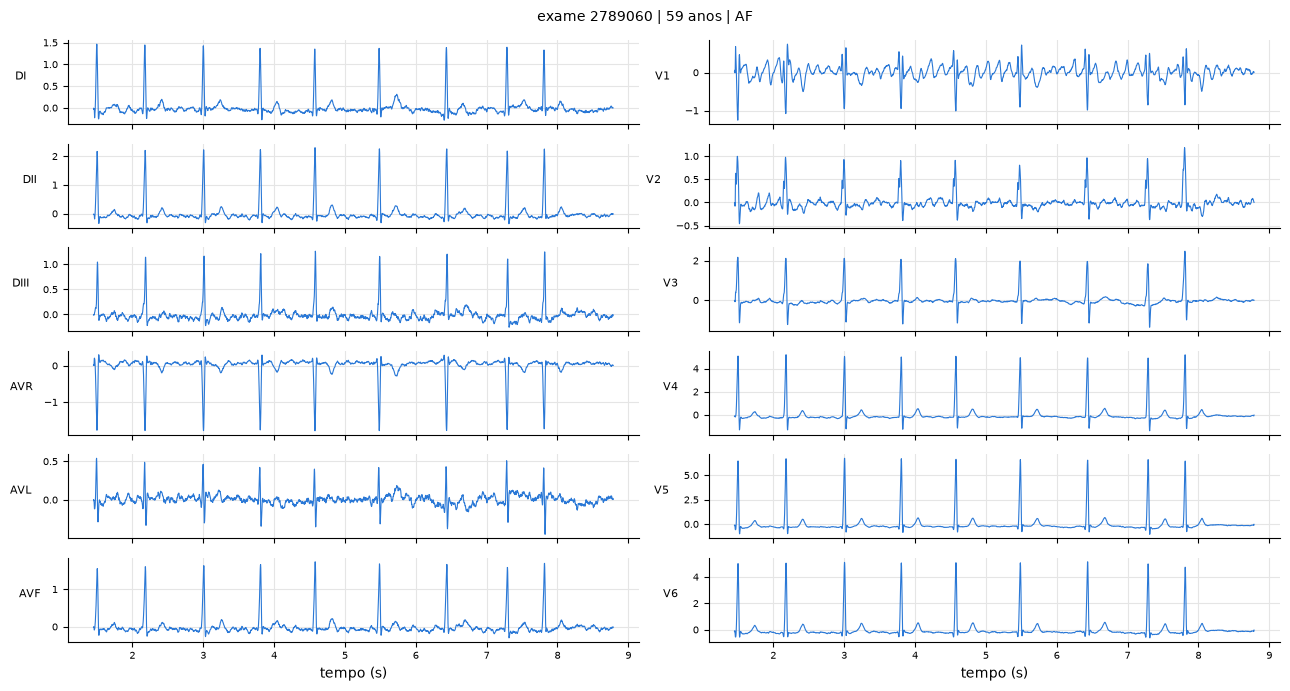

In [10]:
def plotar_ecg(i, titulo=None):
    """Plota as 12 derivações de um exame em duas colunas."""
    sinal = X[i].astype(np.float32)
    tem_sinal = np.where(np.abs(sinal).max(axis=1) > 0)[0]
    trecho = slice(tem_sinal[0], tem_sinal[-1] + 1)
    t = np.arange(sinal.shape[0])[trecho] / 400
    fig, eixos = plt.subplots(6, 2, figsize=(13, 7), sharex=True)
    for k, ax in enumerate(eixos.T.flatten()):
        ax.plot(t, sinal[trecho, k], lw=0.8, color=CORES["1dAVb"])
        ax.set_ylabel(DERIVACOES[k], rotation=0, labelpad=16, fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in eixos[-1]:
        ax.set_xlabel("tempo (s)")
    linha = info.iloc[i]
    marcados = [r for r in ROTULOS if linha[r]] or ["nenhuma alteração"]
    fig.suptitle(titulo or f"exame {linha['exam_id']} | {linha['age']} anos | {', '.join(marcados)}", fontsize=10)
    plt.tight_layout()
    plt.show()


plotar_ecg(int(np.where(info["AF"] & (info[ROTULOS].sum(axis=1) == 1))[0][0]))

**Exemplo de fibrilação atrial:** os intervalos entre os batimentos são irregulares e, em V1, a linha de base "treme" em vez de mostrar a onda P.

Na parte 0 ficaram **19.962 exames de 19.365 pacientes** (39 linhas descartadas: o id 0 de preenchimento e 38 exames zerados), ocupando 2,0 GB em float16. Durações: 7,3 s (11.671 exames), 10,2 s (7.544) e 9,7 s (66).

## 5. Divisão por paciente

Cada **paciente** é sorteado uma única vez para treino (70%), validação (10%) ou teste (20%), usando a lista completa da tabela e a seed fixa. Assim:
- todos os exames de uma pessoa ficam no mesmo grupo;
- adicionar mais partes depois não muda o grupo de ninguém.

A validação serve para escolher épocas, limiares e hiperparâmetros. O teste (e o PTB-XL e o CODE-TEST) só é usado no fim, **nunca para escolher nada**. A proporção 70/10/20 é provisória.

In [11]:
pacientes = np.sort(tabela["patient_id"].unique())
sorteio = np.random.default_rng(SEED).random(len(pacientes))
grupo_do_paciente = pd.Series(np.select([sorteio < 0.7, sorteio < 0.8], ["treino", "validação"], "teste"), index=pacientes)
info["grupo"] = info["patient_id"].map(grupo_do_paciente).values

resumo = info.groupby("grupo")[ROTULOS].sum()
resumo.insert(0, "pacientes", info.groupby("grupo")["patient_id"].nunique())
resumo.insert(0, "exames", info.groupby("grupo").size())
display(resumo.loc[["treino", "validação", "teste"]])

grupos_por_paciente = info.groupby("patient_id")["grupo"].nunique()
print("pacientes em mais de um grupo:", int((grupos_por_paciente > 1).sum()))
indices = {g: np.where(info["grupo"] == g)[0] for g in ["treino", "validação", "teste"]}

,exames,pacientes,1dAVb,RBBB,LBBB,SB,ST,AF
grupo,,,,,,,,
treino,13866,13446,238,381,233,213,300,326
validação,2069,2004,41,48,34,28,37,47
teste,4027,3915,66,109,70,77,86,73


pacientes em mais de um grupo: 0


## 6. Parte A: 6 alterações

Baselines (A0: "sempre negativo" e só idade + sexo) e a CNN 1D (A1), mudando uma coisa por vez. Métricas por rótulo: AUROC, AUPRC e, com o limiar escolhido na validação, sensibilidade, precisão, F1 e especificidade.

**A fazer.**

## 7. Testes externos

O modelo escolhido na validação é testado, **sem retreinar**, no PTB-XL (Alemanha) e no CODE-TEST (gabarito de especialistas).

**A fazer.**

## 8. Parte B: óbito

Óbito em até X anos a partir do primeiro exame. Comparação: B0 idade + sexo; B1 + idade do ECG; B2 CNN só com o ECG; B3 CNN + idade + sexo.

**A fazer.**

## 9. Conclusões e limitações

**A fazer**, depois dos experimentos.

## Extensões (fora das aulas)

Candidatas, só depois do núcleo: saliency/Grad-CAM, focal loss, ResNet 1D maior com GPU, análise de sobrevivência (Cox).